# 04 — Paderborn: The Artificial→Real Baseline (Random Forest)

Notebook 03 delivered a feature table in which *both* artificial (EDM/drilled)
and real (accelerated-lifetime fatigue) damage are detectable — the
precondition for measuring **transfer** rather than feature blindness. This
notebook trains the project's first classifier and asks the RQ4 question in
miniature:

> **A model trained only on damage we can manufacture (artificial) plus a
> healthy baseline — how well does it recognize damage the real world
> produces?**

That is exactly the situation the digital twin puts us in later: the simulator
generates the training data, reality supplies the test set. Paper 4's
cross-testbed collapse (~100 % → 0.12 %) is the cautionary number; here we
measure our own version of the gap on Paderborn:

1. **Experiment A — the headline:** Random Forest trained on
   `K001 + KA01 + KI01` (healthy + artificial OR/IR damage), tested on
   `KA04 + KI04` (real OR/IR damage); 3-class target Healthy / OR / IR.
2. **Experiment B — two reference ceilings:** grouped 5-fold CV *within* the
   training domain (do the features work at all?) and a mixed-domain split
   (what would real training data buy us?).
3. **Ablation by feature family:** all 12 / envelope / envelope fundamentals
   only / time-domain / current — turning notebooks 02–03's qualitative
   claims into classifier numbers.
4. **Error analysis + feature importance:** which windows fool the model and
   which features carry the transfer.

Same data as notebook 03: condition `N15_M07_F10`, 5 bearings × 20 runs ×
15 windows → `data/processed/pu_N15_M07_F10_spectral_features.csv`.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GroupKFold, cross_val_score

df = pd.read_csv(pathlib.Path("../data/processed/pu_N15_M07_F10_spectral_features.csv"))

# fault type (the prediction target) vs damage domain (how the damage was made)
df["Condition"] = df["Status"].map({"Healthy": "Healthy", "OR-art": "OR", "IR-art": "IR",
                                    "OR-real": "OR", "IR-real": "IR"})
df["Domain"] = df["Status"].map({"Healthy": "healthy", "OR-art": "artificial", "IR-art": "artificial",
                                 "OR-real": "real", "IR-real": "real"})
df["Group"] = df["Status"] + "_r" + df["Run"].astype(str)  # one physical 4 s recording

FEATURES_ALL = [c for c in df.columns if c not in ("Status", "Run", "Condition", "Domain", "Group")]
FEATURE_SETS = {
    "All (12)":              FEATURES_ALL,
    "Envelope (5)":          [c for c in FEATURES_ALL if c.startswith("Env_")],
    "Env fundamentals (3)":  ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"],
    "Time-domain (2)":       ["Vib_RMS", "Vib_CrestFactor"],
    "Current/MCSA (5)":      [c for c in FEATURES_ALL if c.startswith("Cur_")],
}
CLASSES = ["Healthy", "OR", "IR"]

# chart tokens: validated light-mode reference palette (dataviz)
C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})

df.groupby(["Domain", "Status"], sort=False).size()

Domain      Status 
healthy     Healthy    300
artificial  OR-art     300
            IR-art     300
real        OR-real    300
            IR-real    300
dtype: int64

## Experiment design — what is a fair split here?

- **No leakage in experiment A:** train and test are **different physical
  bearings**; no window, run, or bearing appears on both sides.
- **Grouped in-domain estimates:** the 15 windows of one 4-second recording
  are strongly correlated, so every cross-validation groups by recording
  (`Group = bearing_run`) — windows of one recording never straddle a fold.
- **No healthy windows in the test set** (our single healthy bearing must stay
  in training). Experiment A therefore measures fault *recognition* on faulty
  data: per-class recall on OR-real/IR-real, and crucially the
  **missed-fault rate** — the share of real-fault windows waved through as
  "Healthy". That is the operationally dangerous error, and it has no
  counterpart in a plain accuracy number.
- **Recording-level score:** a monitoring system sees many windows, so we also
  report a majority vote over the 15 windows of each recording.
- ⚠️ **One-bearing-per-cell caveat:** each class×domain cell is a *single*
  physical bearing (starter subset), so "domain gap" and "bearing identity"
  are confounded — the known limitation of this benchmark. This is a dry run
  that produces a first number, not a paper-grade number; the fix (more
  bearings per cell) is in next steps.

In [2]:
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)

TRAIN = df[df["Domain"].isin(["healthy", "artificial"])]
TEST = df[df["Domain"] == "real"]


def art_to_real(features):
    """Train on healthy + artificial damage, evaluate on the real-damage windows."""
    rf = RandomForestClassifier(**RF_KW).fit(TRAIN[features], TRAIN["Condition"])
    pred = rf.predict(TEST[features])
    acc = (pred == TEST["Condition"]).mean()
    missed = (pred == "Healthy").mean()  # a real fault predicted as healthy
    votes = (pd.DataFrame({"Group": TEST["Group"].values,
                           "true": TEST["Condition"].values, "pred": pred})
             .groupby("Group")
             .agg(true=("true", "first"), pred=("pred", lambda p: p.mode().iloc[0])))
    return rf, pred, acc, missed, (votes["pred"] == votes["true"]).mean()


rf_all, pred_all, acc_all, missed_all, run_acc_all = art_to_real(FEATURES_ALL)
recall = {c: (pred_all[(TEST["Condition"] == c).values] == c).mean() for c in ("OR", "IR")}

print("Experiment A - artificial -> real, all 12 features (600 windows, 40 recordings)")
print(f"  window accuracy    : {acc_all:6.1%}")
print(f"  recording majority : {run_acc_all:6.1%}")
print(f"  OR-real recall     : {recall['OR']:6.1%}")
print(f"  IR-real recall     : {recall['IR']:6.1%}")
print(f"  missed-fault rate  : {missed_all:6.1%}  (real fault predicted 'Healthy')")
print()
print(pd.crosstab(TEST["Status"], pred_all, rownames=["true"], colnames=["predicted"]))

Experiment A - artificial -> real, all 12 features (600 windows, 40 recordings)
  window accuracy    :  20.8%
  recording majority :  12.5%
  OR-real recall     :   0.7%
  IR-real recall     :  41.0%
  missed-fault rate  :  79.2%  (real fault predicted 'Healthy')

predicted  Healthy   IR  OR
true                       
IR-real        177  123   0
OR-real        298    0   2


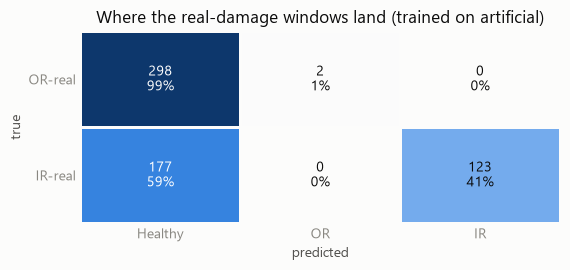

In [3]:
from matplotlib.colors import LinearSegmentedColormap

cm = confusion_matrix(TEST["Condition"], pred_all, labels=CLASSES)[1:]  # true rows: OR, IR
blue_seq = LinearSegmentedColormap.from_list("blue_seq", [SURFACE] + BLUE_RAMP)

fig, ax = plt.subplots(figsize=(5.8, 2.8))
ax.grid(False)
ax.pcolormesh(cm, cmap=blue_seq, vmin=0, vmax=300, edgecolors=SURFACE, linewidth=2)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        n = cm[i, j]
        ax.text(j + 0.5, i + 0.5, f"{n}\n{n / 300:.0%}", ha="center", va="center",
                fontsize=10, color="#ffffff" if n > 150 else INK)
ax.invert_yaxis()
ax.set_xticks([0.5, 1.5, 2.5], CLASSES)
ax.set_yticks([0.5, 1.5], ["OR-real", "IR-real"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Where the real-damage windows land (trained on artificial)")
for s in ("left", "bottom"):
    ax.spines[s].set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

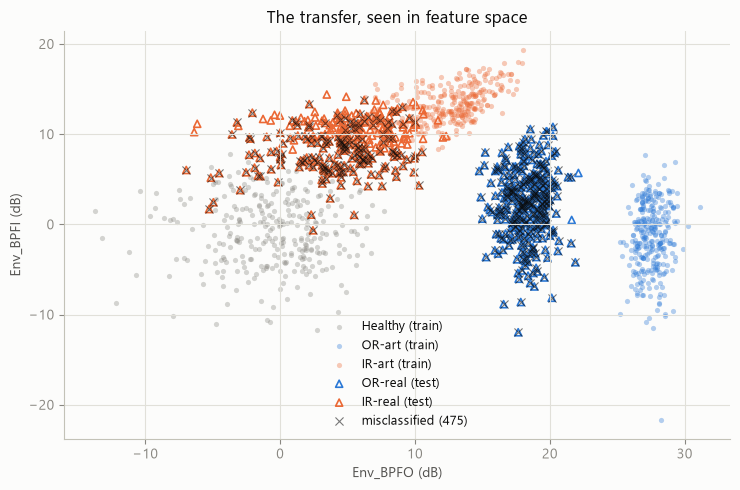

In [4]:
CLASS_COLOR = {"Healthy": MUTED, "OR": C_BLUE, "IR": C_ORANGE}

fig, ax = plt.subplots(figsize=(7.5, 5))
for status, cond in [("Healthy", "Healthy"), ("OR-art", "OR"), ("IR-art", "IR")]:
    sub = TRAIN[TRAIN["Status"] == status]
    ax.scatter(sub["Env_BPFO_dB"], sub["Env_BPFI_dB"], s=14, alpha=0.35, linewidths=0,
               color=CLASS_COLOR[cond], label=f"{status} (train)")
for status, cond in [("OR-real", "OR"), ("IR-real", "IR")]:
    sub = TEST[TEST["Status"] == status]
    ax.scatter(sub["Env_BPFO_dB"], sub["Env_BPFI_dB"], s=26, marker="^", facecolors="none",
               edgecolors=CLASS_COLOR[cond], linewidths=1.2, label=f"{status} (test)")
wrong = pred_all != TEST["Condition"].values
ax.scatter(TEST.loc[wrong, "Env_BPFO_dB"], TEST.loc[wrong, "Env_BPFI_dB"], s=34,
           color=INK, marker="x", linewidths=0.8, alpha=0.55,
           label=f"misclassified ({wrong.sum()})")
ax.set_xlabel("Env_BPFO (dB)")
ax.set_ylabel("Env_BPFI (dB)")
ax.set_title("The transfer, seen in feature space")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Reading the collapse

The model that was *perfect* in its own domain is **worse than guessing** on
real damage (20.8 % vs 33 % chance), and its errors point the dangerous way:
**79 % of real-fault windows are waved through as "Healthy."**

- **OR-real is not borderline — it is invisible: 99 % → Healthy** (298/300),
  despite a clearly visible +18 dB mean BPFO signature. The scatter shows
  why: both real-damage clusters sit in the corridor *between* the healthy
  cloud and their (more severe) artificial counterparts. The forest carved
  its decision surface around the artificial levels it was shown, and the
  corridor belongs to whatever the remaining features vote for — mostly
  Healthy. (The guilty features are named two sections down.)
- **Majority voting makes it worse, not better** (12.5 % of recordings vs
  20.8 % of windows): the failure is systematic per recording, not window
  noise, so aggregation entrenches it. A production monitor that votes over
  windows would *harden* the miss.
- Notebook 03 proved both domains are **detectable** (envelope SNRs well
  above the floor), so this is not feature blindness — it is a
  **severity/level calibration gap**. Exactly the failure mode a digital
  twin must expect: simulated damage will not match real severity levels
  either.

In [5]:
# Experiment B - two reference ceilings for experiment A's number
gkf = GroupKFold(n_splits=5)

# B1: within the training domain (healthy + artificial), grouped by recording
cv_scores = cross_val_score(RandomForestClassifier(**RF_KW), TRAIN[FEATURES_ALL],
                            TRAIN["Condition"], groups=TRAIN["Group"], cv=gkf)

# B2: mixed-domain - train on runs 1-15 of ALL five bearings, test on runs 16-20.
# Optimistic by construction (the same physical bearing sits on both sides), but it
# bounds what real-damage training data buys vs experiment A.
mtrain, mtest = df[df["Run"] <= 15], df[df["Run"] >= 16]
rf_mixed = RandomForestClassifier(**RF_KW).fit(mtrain[FEATURES_ALL], mtrain["Condition"])
mpred = rf_mixed.predict(mtest[FEATURES_ALL])
real16 = (mtest["Domain"] == "real").values

print(f"B1 within-domain grouped CV (healthy+artificial): "
      f"{cv_scores.mean():.1%} +/- {cv_scores.std():.1%}")
print(f"B2 mixed-domain (all bearings, unseen runs)     : "
      f"{(mpred == mtest['Condition']).mean():.1%} overall, "
      f"{(mpred[real16] == mtest['Condition'].values[real16]).mean():.1%} on real damage")
print(f"A  artificial -> real (from above)              : {acc_all:.1%}")

B1 within-domain grouped CV (healthy+artificial): 100.0% +/- 0.0%
B2 mixed-domain (all bearings, unseen runs)     : 100.0% overall, 100.0% on real damage
A  artificial -> real (from above)              : 20.8%


In [6]:
rows = []
for name, feats in FEATURE_SETS.items():
    cv = cross_val_score(RandomForestClassifier(**RF_KW), TRAIN[feats], TRAIN["Condition"],
                         groups=TRAIN["Group"], cv=gkf).mean()
    _, _, acc, missed, run_acc = art_to_real(feats)
    rows.append({"Features": name, "In-domain CV": cv, "Art->Real (window)": acc,
                 "Art->Real (majority)": run_acc, "Missed-fault rate": missed})
ablation = pd.DataFrame(rows).set_index("Features")
ablation.style.format("{:.1%}")

,In-domain CV,Art->Real (window),Art->Real (majority),Missed-fault rate
Features,,,,
All (12),100.0%,20.8%,12.5%,79.2%
Envelope (5),100.0%,40.5%,50.0%,59.5%
Env fundamentals (3),100.0%,76.5%,97.5%,20.8%
Time-domain (2),100.0%,47.2%,50.0%,52.8%
Current/MCSA (5),75.9%,23.0%,20.0%,55.5%


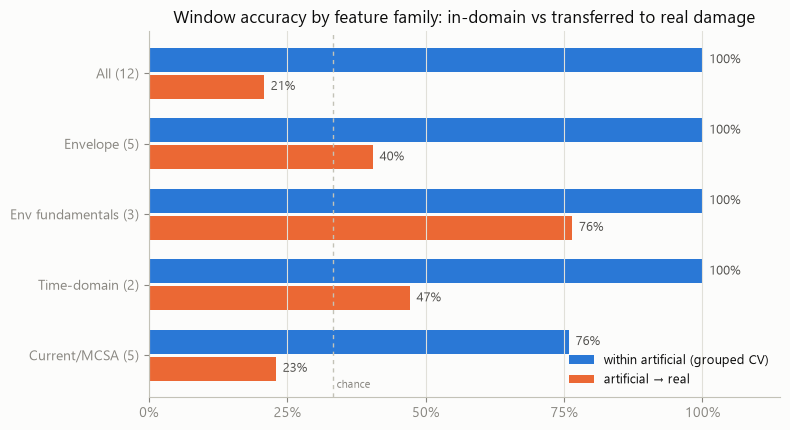

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
y = np.arange(len(ablation))[::-1]
h = 0.34
ax.barh(y + h / 2 + 0.02, ablation["In-domain CV"], height=h, color=C_BLUE,
        label="within artificial (grouped CV)")
ax.barh(y - h / 2 - 0.02, ablation["Art->Real (window)"], height=h, color=C_ORANGE,
        label="artificial → real")
for yy, v in zip(y + h / 2 + 0.02, ablation["In-domain CV"]):
    ax.text(v + 0.012, yy, f"{v:.0%}", va="center", fontsize=9, color=INK2)
for yy, v in zip(y - h / 2 - 0.02, ablation["Art->Real (window)"]):
    ax.text(v + 0.012, yy, f"{v:.0%}", va="center", fontsize=9, color=INK2)
ax.axvline(1 / 3, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(1 / 3 + 0.006, ax.get_ylim()[0] + 0.1, "chance", color=MUTED, fontsize=8, va="bottom")
ax.set_yticks(y, ablation.index)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.14)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0], ["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Window accuracy by feature family: in-domain vs transferred to real damage")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

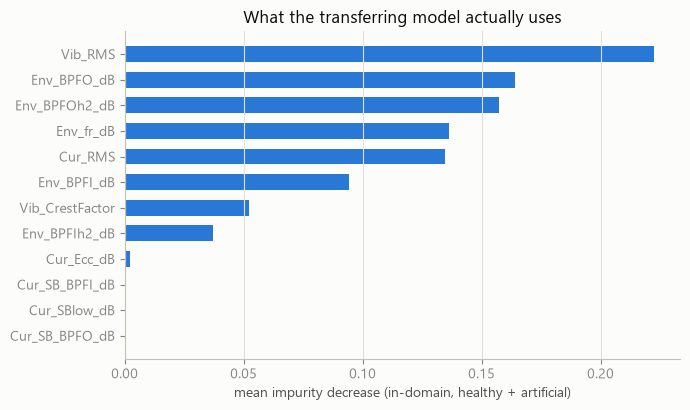

top 4: Vib_RMS, Env_BPFO_dB, Env_BPFOh2_dB, Env_fr_dB


In [8]:
imp = pd.Series(rf_all.feature_importances_, index=FEATURES_ALL).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(imp.index, imp.values, color=C_BLUE, height=0.62)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean impurity decrease (in-domain, healthy + artificial)")
ax.set_title("What the transferring model actually uses")
plt.tight_layout()
plt.show()
print("top 4:", ", ".join(imp.sort_values(ascending=False).index[:4]))

## Naming the poisons

In-domain importance says the forest leans hardest on `Vib_RMS`,
`Env_BPFO_dB`, `Env_BPFOh2_dB`, `Env_fr_dB`. Two of those are traps that
notebooks 02–03 already flagged:

1. **`Env_BPFOh2_dB` is contaminated** (nb03, finding 4): the ≈52.7 Hz rig
   harmonic family puts its 3rd harmonic (≈158 Hz) on top of
   2×BPFO (153.5 Hz), so *healthy* reads ≈15 dB there — the same as OR-real
   (15.9 dB), while OR-art (26.4 dB) is far away. Any split on this feature
   files OR-real under Healthy.
2. **`Vib_RMS` is a bearing-specific level** (nb02): KI04's RMS (0.37) sits
   *below* healthy's (0.40) — nothing like KI01's (0.67). The feature that
   looks best in-domain transfers worst.

The test: strip the model down to the three physics-anchored fundamentals
(`Env_BPFO`, `Env_BPFI`, `Env_fr`) and re-run the transfer.

In [9]:
_, pred_f, acc_f, missed_f, run_f = art_to_real(FEATURE_SETS["Env fundamentals (3)"])
print("Envelope fundamentals only (Env_BPFO, Env_BPFI, Env_fr):")
print(f"  window {acc_f:.1%} | recording majority {run_f:.1%} | missed-fault {missed_f:.1%}")
print()
print(pd.crosstab(TEST["Status"], pred_f, rownames=["true"], colnames=["predicted"]))
print()
print("poison 1 - contaminated harmonic (rig family on 2xBPFO, nb03 finding 4):")
print("  mean Env_BPFOh2_dB:", df.groupby("Status")["Env_BPFOh2_dB"].mean().round(1).to_dict())
print("poison 2 - bearing-specific level:")
print("  mean Vib_RMS      :", df.groupby("Status")["Vib_RMS"].mean().round(2).to_dict())
_, _, acc_fr, _, _ = art_to_real(FEATURE_SETS["Env fundamentals (3)"] + ["Vib_RMS"])
print(f"\nfundamentals + Vib_RMS: window accuracy {acc_fr:.1%}  "
      f"-> that single level feature costs {acc_f - acc_fr:.0%} of transfer")

Envelope fundamentals only (Env_BPFO, Env_BPFI, Env_fr):
  window 76.5% | recording majority 97.5% | missed-fault 20.8%

predicted  Healthy   IR   OR
true                        
IR-real         98  202    0
OR-real         27   16  257

poison 1 - contaminated harmonic (rig family on 2xBPFO, nb03 finding 4):
  mean Env_BPFOh2_dB: {'Healthy': 14.8, 'IR-art': 6.6, 'IR-real': 3.8, 'OR-art': 26.4, 'OR-real': 15.9}
poison 2 - bearing-specific level:
  mean Vib_RMS      : {'Healthy': 0.4, 'IR-art': 0.67, 'IR-real': 0.37, 'OR-art': 0.54, 'OR-real': 0.48}



fundamentals + Vib_RMS: window accuracy 54.0%  -> that single level feature costs 22% of transfer


## Can a little real data close the gap? (RQ4's mitigation hypothesis)

RQ4 hypothesizes that *mixing a modest fraction of real target-domain data into
training recovers most of the lost performance*. The starter subset lets us
test that directly: move `k` randomly chosen real recordings per fault class
(out of 20) into the training set, evaluate on the remaining real recordings,
and average over 10 random draws. `k = 0` is experiment A.

In [10]:
rng = np.random.default_rng(0)
real_groups = {c: sorted(TEST.loc[TEST["Condition"] == c, "Group"].unique())
               for c in ("OR", "IR")}

mix = {0: (np.array([acc_all]), np.array([missed_all]))}
for k in (1, 2, 5):
    accs, misses = [], []
    for _ in range(10):
        chosen = [g for c in ("OR", "IR")
                  for g in rng.choice(real_groups[c], size=k, replace=False)]
        tr = pd.concat([TRAIN, TEST[TEST["Group"].isin(chosen)]])
        te = TEST[~TEST["Group"].isin(chosen)]
        pred = (RandomForestClassifier(**RF_KW)
                .fit(tr[FEATURES_ALL], tr["Condition"]).predict(te[FEATURES_ALL]))
        accs.append((pred == te["Condition"]).mean())
        misses.append((pred == "Healthy").mean())
    mix[k] = (np.array(accs), np.array(misses))

for k, (accs, misses) in mix.items():
    print(f"k={k} real recordings/class in training: "
          f"accuracy on held-out real {accs.mean():6.1%} +/- {accs.std():5.1%}   "
          f"missed-fault {misses.mean():6.1%}")

k=0 real recordings/class in training: accuracy on held-out real  20.8% +/-  0.0%   missed-fault  79.2%
k=1 real recordings/class in training: accuracy on held-out real  99.2% +/-  0.4%   missed-fault   0.8%
k=2 real recordings/class in training: accuracy on held-out real  99.8% +/-  0.2%   missed-fault   0.2%
k=5 real recordings/class in training: accuracy on held-out real  99.9% +/-  0.1%   missed-fault   0.1%


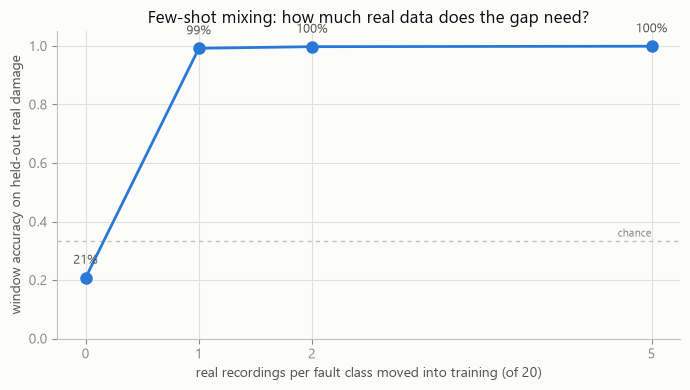

In [11]:
ks = list(mix)
means = [mix[k][0].mean() for k in ks]
stds = [mix[k][0].std() for k in ks]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(ks, means, yerr=stds, color=C_BLUE, lw=2, marker="o", markersize=8,
            capsize=3, ecolor=BASE)
for k, m in zip(ks, means):
    ax.annotate(f"{m:.0%}", (k, m), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, color=INK2)
ax.axhline(1 / 3, color=BASE, lw=1, ls=(0, (3, 3)))
ax.text(ks[-1], 1 / 3 + 0.015, "chance", color=MUTED, fontsize=8, ha="right")
ax.set_xticks(ks)
ax.set_xlabel("real recordings per fault class moved into training (of 20)")
ax.set_ylabel("window accuracy on held-out real damage")
ax.set_ylim(0, 1.05)
ax.set_title("Few-shot mixing: how much real data does the gap need?")
plt.tight_layout()
plt.show()

## Findings (executed 2026-08-06)

1. **Our own domain-gap number (RQ4).** A Random Forest at
   **100.0 % ± 0.0** grouped-CV accuracy in its training domain
   (healthy + artificial) collapses to **20.8 %** on real damage
   (window level; **12.5 %** by recording majority) with a
   **79.2 % missed-fault rate** — below the 33 % chance line, and the errors
   point the dangerous way (real fault → "Healthy"). This is our measured
   counterpart to Paper 4's ~100 % → 0.12 % cross-testbed collapse.
2. **In-domain validation is blind to transferability.** Four feature sets
   all score a flawless 100.0 % CV, yet spread **20.8–76.5 %** under
   transfer. Feature or model selection done on the in-domain metric alone
   cannot see the property we actually need (the mixed-domain ceiling of
   100 % confirms the task is easy once domains align). RQ4 experiments must
   therefore always carry a cross-domain probe.
3. **More features, worse transfer — and the poisons have names.** The
   rig-contaminated 2×BPFO harmonic (healthy 14.8 dB ≈ OR-real 15.9 dB)
   drops OR-real recognition from 257/300 to 3/300 when the two harmonic
   features join the fundamentals (76.5 % → 40.5 %); the bearing-specific
   `Vib_RMS` alone costs 22 points (76.5 % → 54.0 %). Notebook 03's
   "trust the fundamentals" rule is now a classifier-level number, not a
   spectral-plot impression.
4. **Physics-anchored fundamentals transfer best: 76.5 % window — and
   majority voting flips from harmful to decisive: 97.5 %** of recordings
   (39/40) correct, vs 12.5 % with all 12 features. Remaining errors are
   still Healthy-biased (20.8 % missed windows), consistent with the
   severity gap (artificial damage rings ~9–10 dB louder than real).
5. **The MCSA null holds at classifier level:** current-channel features
   reach only 75.9 % even in-domain and 23.0 % transferred — hand-picked
   sidebands carry no usable fault information on this rig (Phase 2:
   learned features).
6. **One real recording per class closes the gap:** k = 1 → **99.2 % ± 0.4**
   (missed-fault 0.8 %), k = 2 → 99.8 %. Domain *alignment* beats data
   volume — Paper 4's lesson, now measured on public data. Design
   implication for the twin: budget for a small real-data calibration set
   (few-shot mixing) instead of hoping zero-shot transfer works.
7. **Caveats.** One physical bearing per class×domain cell (bearing identity
   is confounded with domain — the known limitation of this subset); a
   single operating condition; k > 0 test sets are slightly smaller. These
   are dry-run numbers that shape the method, not paper-grade results.